# Part A 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv("raw_log.csv")
events = pd.read_csv("events.csv")
assays = pd.read_csv("endpoint_assays.csv")

MASS = ["B0_g", "B1_g", "B2_g", "B3_g", "B4_g", "B5_g"]
TEMP = ["T_amb_C", "T_bath_C"]

raw["ts"] = pd.to_datetime(raw["ts_utc"])
start = raw.loc[raw["seq"] == 0, "ts"].iloc[0]
print("rows in file:", len(raw))
print("expected: 78 h x 60 + 1 =", 78 * 60 + 1, "(seq 0 to 4680)")

rows in file: 4696
expected: 78 h x 60 + 1 = 4681 (seq 0 to 4680)


## Duplicate rows 

In [2]:
dups = raw[raw.duplicated("seq", keep=False)]
print("seq values that appear twice:", sorted(dups["seq"].unique()))
print("count:", dups["seq"].nunique())
print("all duplicates identical?", (dups.groupby("seq")[MASS + TEMP].nunique() == 1).all().all())

seq values that appear twice: [np.int64(194), np.int64(427), np.int64(1012), np.int64(1085), np.int64(1586), np.int64(2119), np.int64(2741), np.int64(2996), np.int64(3143), np.int64(3321), np.int64(3487), np.int64(3962), np.int64(4331), np.int64(4406), np.int64(4646)]
count: 15
all duplicates identical? True


## Missing rows

In [3]:
missing = sorted(set(range(0, 4681)) - set(raw["seq"]))
print("missing seq values:", missing if missing else "none")

missing seq values: none


## Rows out of order / uploaded late

places where seq goes backwards:
       seq                ts_utc
3972  3960  2025-03-06T12:00:01Z
4034  4020  2025-03-06T12:01:01Z
4094  4079  2025-03-06T12:02:00Z

rows uploaded > 30 s late: 120 | seq 3960 to 4079
arrived between 2025-03-06T12:00:01Z and 2025-03-06T12:02:00Z
normal jitter on the other rows: -1.0 to 0.0 s


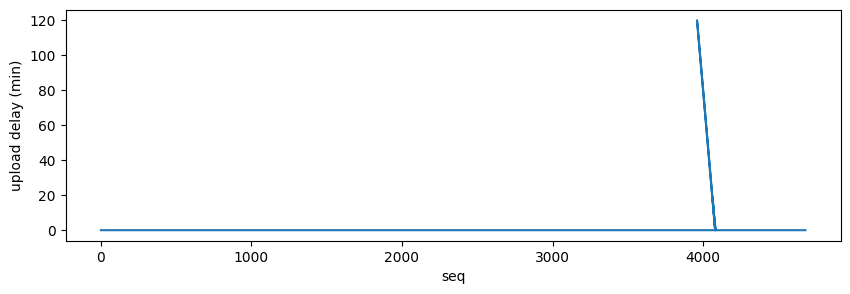

In [4]:
raw["delay_s"] = (raw["ts"] - start).dt.total_seconds() - raw["seq"] * 60
print("places where seq goes backwards:")
print(raw.loc[raw["seq"].diff() < 0, ["seq", "ts_utc"]])

late = raw[raw["delay_s"] > 30].drop_duplicates("seq")
print("\nrows uploaded > 30 s late:", len(late), "| seq", late["seq"].min(), "to", late["seq"].max())
print("arrived between", late["ts_utc"].min(), "and", late["ts_utc"].max())
on_time = raw[raw["delay_s"] <= 30]
print("normal jitter on the other rows:", on_time["delay_s"].min(), "to", on_time["delay_s"].max(), "s")

plt.figure(figsize=(10, 3))
plt.plot(raw["seq"], raw["delay_s"] / 60)
plt.xlabel("seq"); plt.ylabel("upload delay (min)")
plt.show()

Make the dataframe one row per sequence, sorted by sequence, with time rebuilt from sequence.

In [ ]:
df = raw.drop_duplicates("seq").sort_values("seq").set_index("seq")
df["t_h"] = (df.index - 360) / 60     
T = df["T_amb_C"]

## Spikes (a reading far from neighbors)

In [6]:
def spikes(x, limit):
    med = x.rolling(11, center=True, min_periods=1).median()
    return x[(x - med).abs() > limit]

for c in MASS:
    print(c, "spikes at seq:", list(spikes(df[c], 0.5).index))     
for c in TEMP:
    s = spikes(df[c], 3)                                          
    print(c, "spikes at seq:", list(s.index), "values:", list(s.values))

B0_g spikes at seq: [3480]
B1_g spikes at seq: [3480]
B2_g spikes at seq: [3480]
B3_g spikes at seq: [3480]
B4_g spikes at seq: [3480]
B5_g spikes at seq: [3480]
T_amb_C spikes at seq: [] values: []
T_bath_C spikes at seq: [1708, 2656, 3097, 4024] values: [np.float64(85.0), np.float64(85.0), np.float64(85.0), np.float64(85.0)]


In [7]:
df.loc[3478:3482, MASS + TEMP] 

,B0_g,B1_g,B2_g,B3_g,B4_g,B5_g,T_amb_C,T_bath_C
seq,,,,,,,,
3478,520.38,507.58,510.80,513.09,512.71,516.82,21.93,29.94
3479,520.36,507.57,510.80,513.10,512.66,516.75,21.93,30.04
3480,524.48,501.30,518.61,509.90,518.20,512.07,21.86,29.97
3481,520.36,507.57,510.82,513.10,512.67,516.71,21.92,30.04
3482,520.39,507.58,510.80,513.13,512.66,516.74,21.90,29.92


## Steps (a sudden jump that stays)

In [8]:
def steps(x, limit):
    before = x.rolling(10).median()
    after = x[::-1].rolling(10).median()[::-1].shift(-1)
    jump = (after - before).dropna()
    big = jump[jump.abs() > limit]
    out = []
    for i in big.index:                       # keep the biggest jump in each cluster
        if not out or i - out[-1][0] > 20:
            out.append((i, round(jump[i], 2)))
        elif abs(jump[i]) > abs(out[-1][1]):
            out[-1] = (i, round(jump[i], 2))
    return out

m = df[MASS].copy()
m.loc[3480] = np.nan                          # ignore the spike row
for c in MASS:
    print(c, "steps (seq, g):", steps(m[c].interpolate(), 0.3))
print("T_amb_C steps (seq, degC):", steps(T, 0.8))

B0_g steps (seq, g): []
B1_g steps (seq, g): [(361, np.float64(1.05)), (1802, np.float64(-5.13))]
B2_g steps (seq, g): [(359, np.float64(1.02))]
B3_g steps (seq, g): [(358, np.float64(1.02)), (2158, np.float64(1.24)), (2339, np.float64(-0.81))]
B4_g steps (seq, g): [(357, np.float64(1.02)), (2157, np.float64(-1.28)), (2336, np.float64(0.78))]
B5_g steps (seq, g): [(359, np.float64(0.97)), (1803, np.float64(-5.07))]
T_amb_C steps (seq, degC): [(3360, np.float64(1.51))]


## B3 and B4 swapped 

In [9]:
df.loc[[2158, 2159, 2160, 2161, 2338, 2339, 2340, 2341], ["B3_g", "B4_g"]]

,B3_g,B4_g
seq,,
2158,514.06,515.31
2159,514.09,515.30
2160,515.39,514.04
2161,515.33,514.06
2338,514.66,513.82
2339,514.62,513.85
2340,513.84,514.62
2341,513.82,514.63


## Frozen sensor

In [10]:
for c in MASS + TEMP:
    x = df[c]
    run = (x != x.shift()).cumsum()
    n = x.groupby(run).transform("size")
    for _, g in n[n >= 15].groupby(run[n >= 15]):
        i0, i1 = g.index.min(), g.index.max()
        print(f"{c}: frozen at {x[i0]} from seq {i0} to {i1} ({len(g)} readings); "
              f"next reading {x.get(i1 + 1)}")

B2_g: frozen at 511.03 from seq 3059 to 3149 (91 readings); next reading 510.91


## Bath temperature (apart from the spikes)


In [11]:
tb = df.loc[df["T_bath_C"] < 40, "T_bath_C"]
print(f"bath: mean {tb.mean():.2f}, sd {tb.std():.2f}, min {tb.min()}, max {tb.max()} degC")
print(f"room: min {T.min()}, max {T.max()} degC")

bath: mean 30.00, sd 0.05, min 29.8, max 30.24 degC
room: min 20.06, max 25.45 degC


## Does events.csv match the data? 

In [12]:
print(events[["ts_utc", "bottle"]])
for e in pd.to_datetime(events["ts_utc"]):
    print(e, "-> seq", int((e - start).total_seconds() / 60))

def step_at(i):
    return (df.loc[i:i + 9, MASS].mean() - df.loc[i - 10:i - 1, MASS].mean()).round(2)

print("\nstep at seq 360 (pitch, should be +1.00 g in B1-B5, 0 in B0):")
print(step_at(360).to_string())
print("\nstep at seq 1800 (events.csv lists a ~5 mL sample from B1 only):")
print(step_at(1800).to_string())
print("\nfinal volumes from the assay file:")
print(assays[["bottle", "final_volume_mL"]].to_string(index=False))

                 ts_utc          bottle
0  2025-03-03T22:00:00Z  B1,B2,B3,B4,B5
1  2025-03-04T22:00:00Z              B1
2025-03-03 22:00:00+00:00 -> seq 360
2025-03-04 22:00:00+00:00 -> seq 1800

step at seq 360 (pitch, should be +1.00 g in B1-B5, 0 in B0):
B0_g   -0.01
B1_g    1.05
B2_g    1.02
B3_g    1.04
B4_g    1.01
B5_g    0.97

step at seq 1800 (events.csv lists a ~5 mL sample from B1 only):
B0_g   -0.01
B1_g   -5.13
B2_g   -0.05
B3_g   -0.03
B4_g   -0.04
B5_g   -5.07

final volumes from the assay file:
bottle  final_volume_mL
    B1              252
    B4              257


## Temperature sensitivity of each scale 

In [13]:
def jump(s, i=3360, w=30):
    a = s.loc[i - w:i - 1]; b = s.loc[i:i + w - 1]
    pa = np.polyfit(a.index, a.values, 1); pb = np.polyfit(b.index, b.values, 1)
    return np.polyval(pb, i - 0.5) - np.polyval(pa, i - 0.5)

clean_mass = df[MASS].copy()
clean_mass.loc[3480] = np.nan
clean_mass.loc[3059:3149, "B2_g"] = np.nan
sw = (clean_mass.index >= 2160) & (clean_mass.index <= 2339)
clean_mass.loc[sw, ["B3_g", "B4_g"]] = df.loc[sw, ["B4_g", "B3_g"]].values

dT = jump(T)
rows = []
for c in MASS:
    k_step = jump(clean_mass[c]) / dT
    y = clean_mass.loc[3500:4680, c].dropna()
    X = np.column_stack([np.ones(len(y)), y.index / 60, T.loc[y.index]])
    k_fit = np.linalg.lstsq(X, y.values, rcond=None)[0][2]
    rows.append([c, round(jump(clean_mass[c]), 3), round(k_step, 4), round(k_fit, 4)])
K = pd.DataFrame(rows, columns=["channel", "jump_at_3360_g", "k_step_g_per_C", "k_fit_g_per_C"]).set_index("channel")
K["k_g_per_C"] = K[["k_step_g_per_C", "k_fit_g_per_C"]].mean(axis=1).round(4)
K["k_unc"] = ((K["k_step_g_per_C"] - K["k_fit_g_per_C"]).abs() / 2).round(4)
print(f"room temperature jump at seq 3360: {dT:.2f} degC")
K

room temperature jump at seq 3360: 1.53 degC


,jump_at_3360_g,k_step_g_per_C,k_fit_g_per_C,k_g_per_C,k_unc
channel,,,,,
B0_g,0.065,0.0427,0.0498,0.0462,0.0035
B1_g,-0.053,-0.0351,-0.0327,-0.0339,0.0012
B2_g,0.127,0.0834,0.0753,0.0794,0.0040
B3_g,0.030,0.0198,0.0171,0.0184,0.0014
B4_g,-0.098,-0.0645,-0.0793,-0.0719,0.0074
B5_g,0.078,0.0512,0.0175,0.0344,0.0168


## Blank (B0): evaporation

In [14]:
b0 = clean_mass["B0_g"] - K.loc["B0_g", "k_g_per_C"] * T
b0 = b0.dropna()
evap = np.polyfit(b0.index / 60, b0.values, 1)[0]
resid = b0 - np.polyval(np.polyfit(b0.index / 60, b0.values, 1), b0.index / 60)
print(f"B0 evaporation: {evap:.4f} g/h  ->  {abs(evap) * 72:.2f} g over 72 h")
print(f"B0 scatter after removing evaporation and temperature: sd {resid.std():.3f} g")

B0 evaporation: -0.0163 g/h  ->  1.18 g over 72 h
B0 scatter after removing evaporation and temperature: sd 0.024 g


## Is any bottle still losing mass at the end?

In [15]:
for c in MASS:
    y = (clean_mass[c] - K.loc[c, "k_g_per_C"] * T).loc[4080:4680].dropna()
    rate = -np.polyfit(y.index / 60, y.values, 1)[0]
    print(f"{c}: losing {rate:.3f} g/h   (extra vs blank: {rate - abs(evap):+.3f} g/h)")

B0_g: losing 0.020 g/h   (extra vs blank: +0.004 g/h)
B1_g: losing 0.015 g/h   (extra vs blank: -0.001 g/h)
B2_g: losing 0.030 g/h   (extra vs blank: +0.014 g/h)
B3_g: losing 0.022 g/h   (extra vs blank: +0.005 g/h)
B4_g: losing 0.028 g/h   (extra vs blank: +0.012 g/h)
B5_g: losing 0.040 g/h   (extra vs blank: +0.024 g/h)


## B2 against the other S1 bottles

In [16]:
cm = clean_mass.copy()
for c in ["B1_g", "B5_g"]:
    cm.loc[1800:, c] -= cm.loc[1800:1809, c].mean() - cm.loc[1790:1799, c].mean()

loss = {}
for c in MASS:
    y = cm[c] - K.loc[c, "k_g_per_C"] * T
    loss[c] = y.loc[360:369].mean() - y.loc[4671:4680].mean() - abs(evap) * 72
loss = pd.Series(loss).round(2)
print("weight loss pitch -> 72 h, corrected (g):")
print(loss.to_string())
print(f"\nB2 minus mean(B1, B3): {loss['B2_g'] - (loss['B1_g'] + loss['B3_g']) / 2:.2f} g")

weight loss pitch -> 72 h, corrected (g):
B0_g     0.03
B1_g     8.23
B2_g     9.52
B3_g     8.74
B4_g     8.10
B5_g    14.63

B2 minus mean(B1, B3): 1.04 g


## build the clean dataset

In [17]:
clean = df[["ts_utc", "t_h"] + MASS + TEMP].copy()
clean["ts_true"] = start + pd.to_timedelta(clean.index * 60, unit="s")
for c in MASS + TEMP:
    clean[c + "_clean"] = clean[c]
clean["flag"] = ""
def flag(rows, text):
    clean.loc[rows, "flag"] += text + ";"

# fixed
flag(late["seq"].values, "late_upload_time_from_seq")
clean.loc[sw, ["B3_g_clean", "B4_g_clean"]] = clean.loc[sw, ["B4_g", "B3_g"]].values
flag(clean.index[sw], "B3_B4_swap_fixed")
for c in ["B1_g", "B5_g"]:
    s = clean.loc[1800:1809, c].mean() - clean.loc[1790:1799, c].mean()
    clean.loc[1800:, c + "_clean"] -= s
flag(clean.loc[1800:].index, "B1_sample_step_removed;B5_unlogged_step_removed")
# dropped
clean.loc[3480, [c + "_clean" for c in MASS]] = np.nan
flag([3480], "mass_glitch_row_dropped")
bad = clean.index[clean["T_bath_C"] > 40]
clean.loc[bad, "T_bath_C_clean"] = np.nan
flag(bad, "T_bath_spike_dropped")
clean.loc[3059:3149, "B2_g_clean"] = np.nan
flag(clean.loc[3059:3149].index, "B2_frozen_dropped")
# flagged only
flag(clean.loc[3360:].index, "room_temp_step")

clean.to_csv("clean_log.csv")
K.to_csv("temperature_coefficients.csv")
print("saved clean_log.csv", clean.shape, "and temperature_coefficients.csv")

saved clean_log.csv (4681, 20) and temperature_coefficients.csv


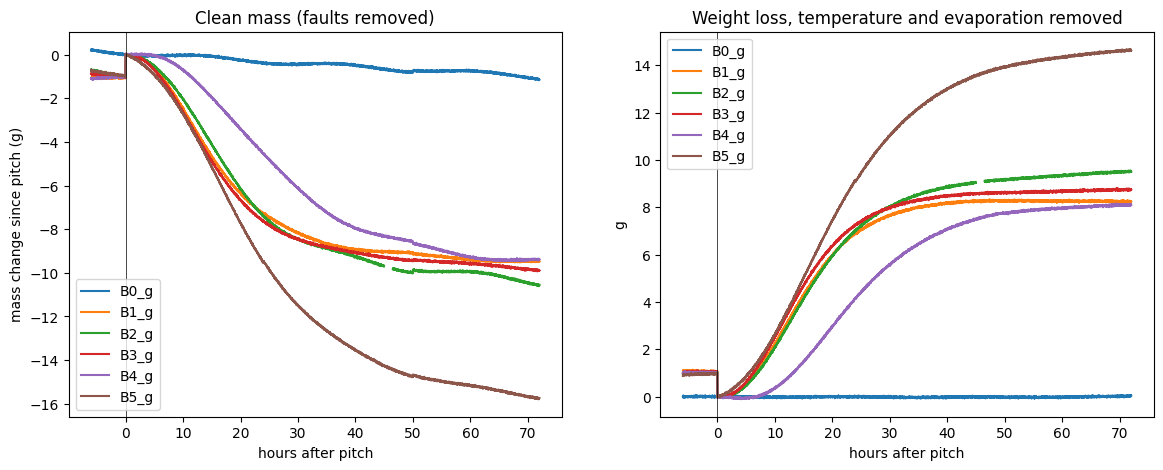

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for c in MASS:
    y = clean[c + "_clean"]
    axes[0].plot(clean["t_h"], y - y.loc[360:369].mean(), label=c)
    yc = y - K.loc[c, "k_g_per_C"] * T - evap * (clean.index - 360) / 60
    axes[1].plot(clean["t_h"], -(yc - yc.loc[360:369].mean()), label=c)
axes[0].set_title("Clean mass (faults removed)"); axes[0].set_ylabel("mass change since pitch (g)")
axes[1].set_title("Weight loss, temperature and evaporation removed"); axes[1].set_ylabel("g")
for a in axes:
    a.axvline(0, color="k", lw=0.5); a.set_xlabel("hours after pitch"); a.legend()
plt.show()